# Large-Scale Simulation and Analysis

This notebook runs the full simulation grid, generates the report figures, and tests the confirmation depth recommended by Nakamoto's approximation.

## Setup

In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import theory
import simulator

import stats_utils


Q_GRID = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45]
Z_GRID = list(range(0, 13))
N_TRIALS = 1_000_000
MASTER_SEED = 2026

RESULTS_DIR = Path("results")
FIGURES_DIR = Path("figures")
RESULTS_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

# Project API
rosenfeld = theory.rosenfeld
nakamoto = theory.attacker_success_probability
simulate_attack_fast = simulator.simulate_attack_fast
wilson_interval_array = stats_utils.wilson_interval_array


## 5.1 Run the grid

Each `(q, z)` cell receives an independent seed generated from a master `SeedSequence`. The CSV stores raw success counts as well as estimates, so confidence intervals can be computed later.

Existing results are loaded instead of rerunning the simulation.

In [9]:
def run_grid():
    n_cells = len(Q_GRID) * len(Z_GRID)
    seeds = np.random.SeedSequence(MASTER_SEED).generate_state(n_cells)

    rows = []
    i = 0
    for q in Q_GRID:
        for z in Z_GRID:
            seed = int(seeds[i])
            i += 1

            successes = int(
                simulate_attack_fast(q, z, N_TRIALS, seed)
            )
            p_hat = successes / N_TRIALS
            se = np.sqrt(p_hat * (1.0 - p_hat) / N_TRIALS)

            rows.append({
                "q": q,
                "z": z,
                "N": N_TRIALS,
                "successes": successes,
                "p_hat": p_hat,
                "se": se,
                "rosenfeld": rosenfeld(q, z),
                "nakamoto": nakamoto(q, z),
            })

    return pd.DataFrame(rows)


grid_path = RESULTS_DIR / "grid_N1e6_seed2026.csv"

if grid_path.exists():
    grid_df = pd.read_csv(grid_path)
else:
    grid_df = run_grid()
    grid_df.to_csv(grid_path, index=False)

display(grid_df.head())
print(f"Loaded {len(grid_df)} rows from {grid_path}")

,q,z,N,successes,p_hat,se,rosenfeld,nakamoto
0,0.05,0,1000000,1000000,1.000000,0.000000,1.000000,1.000000
1,0.05,1,1000000,100118,0.100118,0.000300,0.100000,0.101204
2,0.05,2,1000000,14499,0.014499,0.000120,0.014500,0.012646
3,0.05,3,1000000,2321,0.002321,0.000048,0.002316,0.001641
4,0.05,4,1000000,370,0.000370,0.000019,0.000387,0.000216


Loaded 117 rows from results/grid_N1e6_seed2026.csv


### Rare-event cells

With one million trials, estimates based on very few successes have high relative error. Keep these rows in the dataset. If there are zero successes, the rule of three gives an approximate 95% upper bound of `3/N`.

In [10]:
grid_df["expected_successes_rosenfeld"] = (
    grid_df["rosenfeld"] * grid_df["N"]
)
grid_df["zero_success_upper_95"] = np.where(
    grid_df["successes"] == 0,
    3 / grid_df["N"],
    np.nan,
)

display(
    grid_df.loc[
        (grid_df["successes"] <= 2),
        ["q", "z", "N", "successes", "p_hat",
         "expected_successes_rosenfeld", "zero_success_upper_95"]
    ]
)

,q,z,N,successes,p_hat,expected_successes_rosenfeld,zero_success_upper_95
7,0.05,7,1000000,2,0.000002,2.051090,NaN
8,0.05,8,1000000,0,0.000000,0.365915,0.000003
9,0.05,9,1000000,0,0.000000,0.065743,0.000003
10,0.05,10,1000000,0,0.000000,0.011879,0.000003
11,0.05,11,1000000,0,0.000000,0.002156,0.000003
12,0.05,12,1000000,0,0.000000,0.000393,0.000003
25,0.10,12,1000000,1,0.000001,0.935154,NaN


## 5.2 Figure 1 — Success probability versus confirmations

The y-axis is logarithmic. Rosenfeld is shown as a solid line, Nakamoto as a dashed line, and simulation estimates as points with approximate 95% Wald error bars. Zero-success estimates are marked at `3/N`, their rule-of-three upper bound.

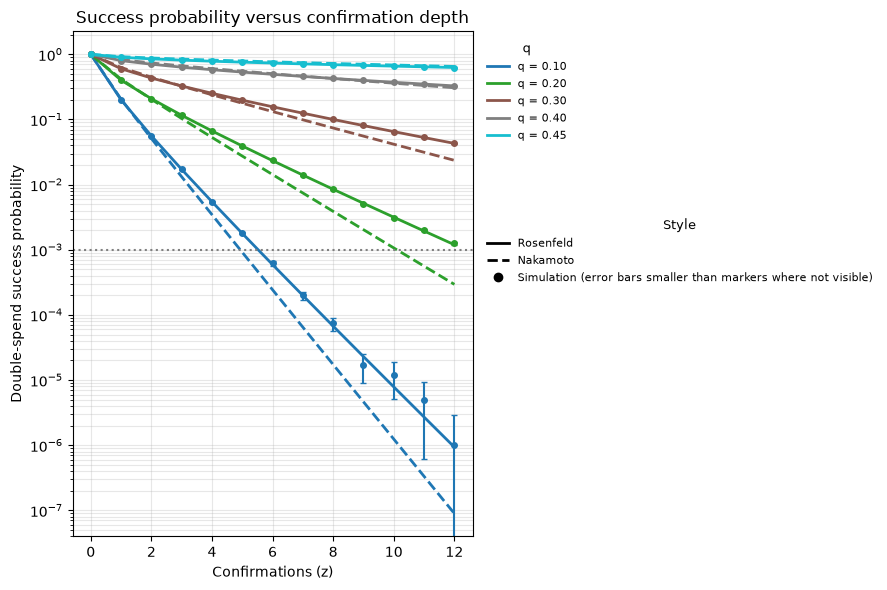

In [11]:
from matplotlib.lines import Line2D

PLOT_Q_VALUES = [0.10, 0.20, 0.30, 0.40, 0.45]
colors = plt.get_cmap("tab10", len(PLOT_Q_VALUES))

fig, ax = plt.subplots(figsize=(9, 6))

color_handles = []
style_handles = [
    Line2D([0], [0], color="black", lw=2, linestyle="-", label="Rosenfeld"),
    Line2D([0], [0], color="black", lw=2, linestyle="--", label="Nakamoto"),
    Line2D([0], [0], color="black", lw=2, linestyle="None", marker="o", label="Simulation (error bars smaller than markers where not visible)"),
]

for i, q in enumerate(PLOT_Q_VALUES):
    subset = grid_df.loc[grid_df["q"] == q].sort_values("z")
    color = colors(i)
    color_handles.append(Line2D([0], [0], color=color, lw=2, label=f"q = {q:.2f}"))

    ax.plot(subset["z"], subset["rosenfeld"], "-", color=color, linewidth=2)
    ax.plot(subset["z"], subset["nakamoto"], "--", color=color, linewidth=2)

    positive = subset["successes"] > 0
    ax.errorbar(
        subset.loc[positive, "z"],
        subset.loc[positive, "p_hat"],
        yerr=1.96 * subset.loc[positive, "se"],
        fmt="o", color=color, capsize=2, markersize=4,
    )

ax.axhline(1e-3, color="gray", linestyle=":")
ax.set_yscale("log")
ax.set_xlabel("Confirmations (z)")
ax.set_ylabel("Double-spend success probability")
ax.set_title("Success probability versus confirmation depth")
ax.grid(True, which="both", alpha=0.3)

legend_colors = ax.legend(handles=color_handles, title="q", fontsize=8, title_fontsize=9,
                          loc="upper left", bbox_to_anchor=(1.01, 1.00), frameon=False)
legend_styles = ax.legend(handles=style_handles, title="Style", fontsize=8, title_fontsize=9,
                         loc="upper left", bbox_to_anchor=(1.01, 0.65), frameon=False)
ax.add_artist(legend_colors)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig1_p_vs_z.pdf", bbox_inches="tight")
plt.show()

## 5.3 Figure 2 — Minimum confirmations for a 0.1% risk threshold

This figure compares the minimum confirmation depth required to reduce the theoretical success probability below `0.001`.

The helper below searches the existing theory functions directly, avoiding assumptions about the argument order of a project-specific `min_confirmations` helper.

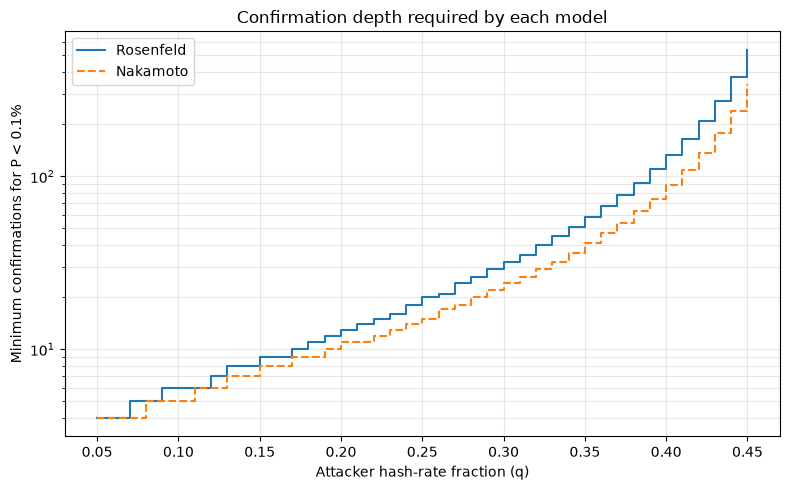

At q = 0.45:
Rosenfeld: 539
Nakamoto: 340


In [12]:
RISK_THRESHOLD = 0.001

q_curve = np.round(np.arange(0.05, 0.451, 0.01), 2)
z_rosenfeld = [
    theory.min_confirmations(rosenfeld, q, threshold=RISK_THRESHOLD) for q in q_curve
]
z_nakamoto = [
    theory.min_confirmations(nakamoto, q, threshold=RISK_THRESHOLD) for q in q_curve
]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(q_curve, z_rosenfeld, "-", drawstyle="steps-post", label="Rosenfeld")
ax.plot(q_curve, z_nakamoto, "--", drawstyle="steps-post", label="Nakamoto")
ax.set_yscale("log")
ax.set_xlabel("Attacker hash-rate fraction (q)")
ax.set_ylabel("Minimum confirmations for P < 0.1%")
ax.set_title("Confirmation depth required by each model")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(FIGURES_DIR / "fig2_min_confirmations.pdf",
            bbox_inches="tight")
plt.show()

print("At q = 0.45:")
print("Rosenfeld:", theory.min_confirmations(rosenfeld, 0.45, threshold=RISK_THRESHOLD))
print("Nakamoto:", theory.min_confirmations(nakamoto, 0.45, threshold=RISK_THRESHOLD))

## 5.4 Is Nakamoto's recommended confirmation depth safe?

For each attacker fraction, simulate the confirmation depth recommended by Nakamoto for a target risk below `0.1%`. Compare the observed estimate with both the promised risk (`0.001`) and Rosenfeld's probability.

The confirmation depths below are the values used in the project analysis.

In [13]:
NAKAMOTO_RECOMMENDED_Z = {
    0.10: 5,
    0.15: 8,
    0.20: 11,
    0.25: 15,
    0.30: 24,
    0.35: 41,
    0.40: 89,
    0.45: 340,
}

N_SAFETY = 1_000_000
SAFETY_MASTER_SEED = 52026
safety_seeds = np.random.SeedSequence(
    SAFETY_MASTER_SEED
).generate_state(len(NAKAMOTO_RECOMMENDED_Z))

def z_score_against_probability(p_hat, p_reference, n):
    se = np.sqrt(p_reference * (1.0 - p_reference) / n)
    if se == 0:
        return np.nan
    return (p_hat - p_reference) / se


def run_nakamoto_safety_experiment():
    rows = []
    for i, (q, z) in enumerate(NAKAMOTO_RECOMMENDED_Z.items()):
        seed = int(safety_seeds[i])
        successes = int(
            simulate_attack_fast(q, z, N_SAFETY, seed)
        )
        p_hat = successes / N_SAFETY
        se = np.sqrt(p_hat * (1.0 - p_hat) / N_SAFETY)
        p_rosenfeld = rosenfeld(q, z)

        rows.append({
            "q": q,
            "z_nakamoto": z,
            "N": N_SAFETY,
            "successes": successes,
            "p_hat": p_hat,
            "se": se,
            "promised_risk": RISK_THRESHOLD,
            "rosenfeld": p_rosenfeld,
            "z_vs_0.001": z_score_against_probability(
                p_hat, RISK_THRESHOLD, N_SAFETY
            ),
            "z_vs_rosenfeld": z_score_against_probability(
                p_hat, p_rosenfeld, N_SAFETY
            ),
            "risk_multiple": p_hat / RISK_THRESHOLD,
        })

    df = pd.DataFrame(rows)
    df["wilson_lo"], df["wilson_hi"] = wilson_interval_array(df["successes"], df["N"])
    df["ci_excludes_0.001"] = df["wilson_lo"] > RISK_THRESHOLD
    df["ci_contains_rosenfeld"] = (
        (df["wilson_lo"] <= df["rosenfeld"]) & (df["rosenfeld"] <= df["wilson_hi"])
    )
    return df

safety_df = run_nakamoto_safety_experiment()
display(safety_df)
safety_path = RESULTS_DIR / "nakamoto_safety_N1e6.csv"
safety_df.to_csv(safety_path, index=False)
print(f"Saved: {safety_path}")

,q,z_nakamoto,N,successes,p_hat,se,promised_risk,rosenfeld,z_vs_0.001,z_vs_rosenfeld,risk_multiple,wilson_lo,wilson_hi,ci_excludes_0.001,ci_contains_rosenfeld
0,0.10,5,1000000,1783,0.001783,0.000042,0.001,0.001782,24.773024,0.027505,1.783,0.001702,0.001868,True,True
1,0.15,8,1000000,1261,0.001261,0.000035,0.001,0.001219,8.257675,1.197457,1.261,0.001193,0.001332,True,True
2,0.20,11,1000000,1948,0.001948,0.000044,0.001,0.001939,29.993393,0.195635,1.948,0.001863,0.002036,True,True
3,0.25,15,1000000,3509,0.003509,0.000059,0.001,0.003569,79.381247,-0.998203,3.509,0.003395,0.003627,True,True
4,0.30,24,1000000,3991,0.003991,0.000063,0.001,0.004001,94.631052,-0.153207,3.991,0.003869,0.004116,True,True
5,0.35,41,1000000,5615,0.005615,0.000075,0.001,0.005563,146.012138,0.705786,5.615,0.005470,0.005763,True,True
6,0.40,89,1000000,7011,0.007011,0.000083,0.001,0.007106,190.179624,-1.129859,7.011,0.006849,0.007176,True,True
7,0.45,340,1000000,8855,0.008855,0.000094,0.001,0.008968,248.521202,-1.197536,8.855,0.008673,0.009041,True,True


Saved: results/nakamoto_safety_N1e6.csv


### Interpretation

A positive `z_vs_0.001` indicates that the simulated risk exceeds Nakamoto's target. A `z_vs_rosenfeld` near zero indicates agreement with the Rosenfeld prediction. The `risk_multiple` column reports the observed risk as a multiple of `0.1%`.

In [14]:
display(
    safety_df[
        ["q", "z_nakamoto", "p_hat", "rosenfeld",
         "z_vs_0.001", "z_vs_rosenfeld", "risk_multiple"]
    ].round(6)
)

print("All estimates exceed the 0.1% target:",
      bool((safety_df["p_hat"] > RISK_THRESHOLD).all()))
print("All |z-scores vs Rosenfeld| < 2:",
      bool((safety_df["z_vs_rosenfeld"].abs() < 2).all()))

,q,z_nakamoto,p_hat,rosenfeld,z_vs_0.001,z_vs_rosenfeld,risk_multiple
0,0.10,5,0.001783,0.001782,24.773024,0.027505,1.783
1,0.15,8,0.001261,0.001219,8.257675,1.197457,1.261
2,0.20,11,0.001948,0.001939,29.993393,0.195635,1.948
3,0.25,15,0.003509,0.003569,79.381247,-0.998203,3.509
4,0.30,24,0.003991,0.004001,94.631052,-0.153207,3.991
5,0.35,41,0.005615,0.005563,146.012138,0.705786,5.615
6,0.40,89,0.007011,0.007106,190.179624,-1.129859,7.011
7,0.45,340,0.008855,0.008968,248.521202,-1.197536,8.855


All estimates exceed the 0.1% target: True
All |z-scores vs Rosenfeld| < 2: True


## Output files

- `results/grid_N1e6_seed2026.csv`
- `results/nakamoto_safety_N1e6.csv`
- `figures/fig1_p_vs_z.pdf`
- `figures/fig2_min_confirmations.pdf`